# Series MODIS y VIIRS comparables para Perú — entrega empírica
Dos líneas con la misma unidad: detecciones reportadas ajustadas a una respuesta instrumental
común. Conservamos instrumentos y plataformas originales. Un punto no equivale a un incendio.
Esta entrega NO recupera toda la cobertura histórica: `coverage_corrected=False`.
Los huecos representan información no disponible; no se convierten en cero incendios.

Modo completo de validación: separación temporal, bloques espaciales reservados, pruebas
sintéticas y bootstrap por bloques. Este notebook muestra los artefactos ya calculados;
el entrenamiento reproducible está en `calibration.py` y `fit_calibration.py`.

In [1]:
from pathlib import Path
import os,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path(os.environ.get('FIRMS_ARTIFACTS_DIR','outputs')).resolve()
P=ROOT/'23_demo_historica'
meta=json.loads((P/'series/series_metadata.json').read_text())
model=json.loads((P/'model/model.json').read_text())
prep=json.loads((P/'data/preparation.json').read_text())
national=pd.read_csv(P/'series/national_series.csv',parse_dates=['week_start_utc'])
factors=pd.read_csv(P/'model/calibration_factors.csv').drop_duplicates(['platform','factor'])
display(pd.DataFrame([{'instrumento':'MODIS','inicio':'2000-11-06','fin':'2026-07-26'},
    {'instrumento':'VIIRS','inicio':'2012-02-06','fin':'2026-07-26'}]))
display(pd.Series({'detecciones retenidas':prep['retained_detections'],'celdas de 10 km':prep['cell_count'],
    'registros celda-semana-instrumento positivos':meta['cell_rows_with_records'],
    'cobertura histórica corregida':meta['coverage_corrected']}))

,instrumento,inicio,fin
0,MODIS,2000-11-06,2026-07-26
1,VIIRS,2012-02-06,2026-07-26


detecciones retenidas                           2228157
celdas de 10 km                                   13405
registros celda-semana-instrumento positivos     513756
cobertura histórica corregida                     False
dtype: object

## 1. Selección y unidad de análisis
Solo productos científicos SP, `type=0`, coordenadas dentro de la unión departamental MINAM
y semanas completas UTC de lunes a domingo. No se mezclan productos NRT, cuyo `type` falta.
El límite MINAM es generalizado (aproximadamente 500 m y 100 m en dos departamentos):
una clasificación cerca de la frontera puede cambiar con un límite más detallado.
Malla LAEA de área equivalente, celdas de 10 × 10 km, recortadas a Perú.
El identificador `laea10_ix_iy` se obtiene por división entera de las coordenadas proyectadas.
Las celdas de frontera tienen menos de 100 km² dentro del país.

In [2]:
display(pd.read_csv(P/'data/selection_flow.csv'))
cells=pd.read_csv(P/'data/cells.csv')
display(cells.head(5))
assert cells.cell_id.is_unique
assert np.isclose(cells.country_area_km2.sum(),prep['country_area_km2'])
assert national.groupby(['week_start_utc','instrument']).size().max()==1
print('Geometría y unicidad verificadas. No se contabilizan satélites adicionales como incendios adicionales.')

,source,type0_in_period,outside_generalized_MINAM_boundary,retained
0,fire_archive_M-C61_848898.csv,350706,578,350128
1,fire_archive_J1V-C2_848899.csv,622509,2450,620059
2,fire_archive_J2V-C2_848900.csv,234150,1117,233033
3,fire_archive_SV-C2_848901.csv,1028649,3712,1024937


,cell_id,ix,iy,center_lon,center_lat,country_area_km2
0,laea10_48_-104,48,-104,-70.425828,-18.331142,31.959757
1,laea10_49_-104,49,-104,-70.331488,-18.329711,40.704646
2,laea10_50_-104,50,-104,-70.237147,-18.328252,38.657564
3,laea10_51_-104,51,-104,-70.142804,-18.326764,33.128720
4,laea10_52_-104,52,-104,-70.048459,-18.325246,1.481119


Geometría y unicidad verificadas. No se contabilizan satélites adicionales como incendios adicionales.


## 2. Qué armonizamos matemáticamente
Sea n_s,g el conteo reportado por plataforma s en celda-semana g. El modelo conceptual es
E[n_s,g] = actividad_g × exposición_s,g × respuesta_s.
Sin máscaras completas, la exposición es desconocida: no podemos identificar actividad física.
Por ello calibramos una **respuesta relativa empírica**, que también puede absorber diferencias
de exposición. No afirmamos que los factores sean solo sensibilidad del detector.

Condicionamos los conteos de dos plataformas en su suma N: la actividad compartida se cancela
bajo el supuesto Poisson y obtenemos una distribución binomial. Como los CSV solo dan positivos,
condicionamos además a que ambos conteos sean positivos (1 ≤ n ≤ N−1). Los pares 1+1 no informan
el contraste y se excluyen. Los ceros con cobertura verificada se podrán incorporar después.

Fijamos la media geométrica de las respuestas Aqua y Suomi-NPP en 1. La salida es
**conteo comparable = conteo reportado / respuesta estimada**. No es una escala arbitraria 0–100,
ni el número verdadero de incendios, ni una predicción del conteo de otro satélite.

In [3]:
display(factors[['platform','factor','factor_low','factor_high']].reset_index(drop=True).round(4))
a=float(factors.loc[factors.platform.eq('Aqua'),'factor'].iloc[0])
v=float(factors.loc[factors.platform.eq('Suomi-NPP'),'factor'].iloc[0])
display(pd.DataFrame({'plataforma':['Aqua','Suomi-NPP'],'conteo reportado':[1,7],
    'factor':[a,v],'conteo en escala común':[a,7*v]}).round(4))
print('Un resultado decimal es una estimación en la escala común, no una fracción de incendio observado.')

,platform,factor,factor_low,factor_high
0,Aqua,1.9938,1.9496,2.0284
1,Suomi-NPP,0.5016,0.4930,0.5129
2,Terra,4.3115,4.1202,4.5395
3,NOAA-20,0.5128,0.5033,0.5256
4,NOAA-21,0.5209,0.4830,0.5397


,plataforma,conteo reportado,factor,conteo en escala común
0,Aqua,1,1.9938,1.9938
1,Suomi-NPP,7,0.5016,3.5109


Un resultado decimal es una estimación en la escala común, no una fracción de incendio observado.


## 3. Plataformas y continuidad
Se elige una plataforma por instrumento y semana en todo Perú: Aqua y Suomi-NPP son las
referencias. Se usa Terra antes de Aqua; NOAA-20/21 sirven de puente cuando Suomi-NPP no
tiene registros en el país durante esa semana. Ausencia nacional de registros no prueba un fallo.
No se rellenan huecos locales incorporando puntos de otros satélites. Tampoco se suman
plataformas: eso produciría incrementos artificiales al añadir instrumentos.
Terra después de 2023 no se usa como respaldo. Suomi-NPP antes de febrero de 2012 se excluye.

La extrapolación hacia 2000–2002 supone estabilidad de la relación Terra–Aqua estimada después;
esa estabilidad no está garantizada. El período 2026 también queda fuera de la validación final.

,instrument,selected_platform,semanas
0,MODIS,Aqua,1253
1,MODIS,Terra,79
2,MODIS,NaN,10
3,VIIRS,NOAA-20,1
4,VIIRS,Suomi-NPP,754
5,VIIRS,NaN,587


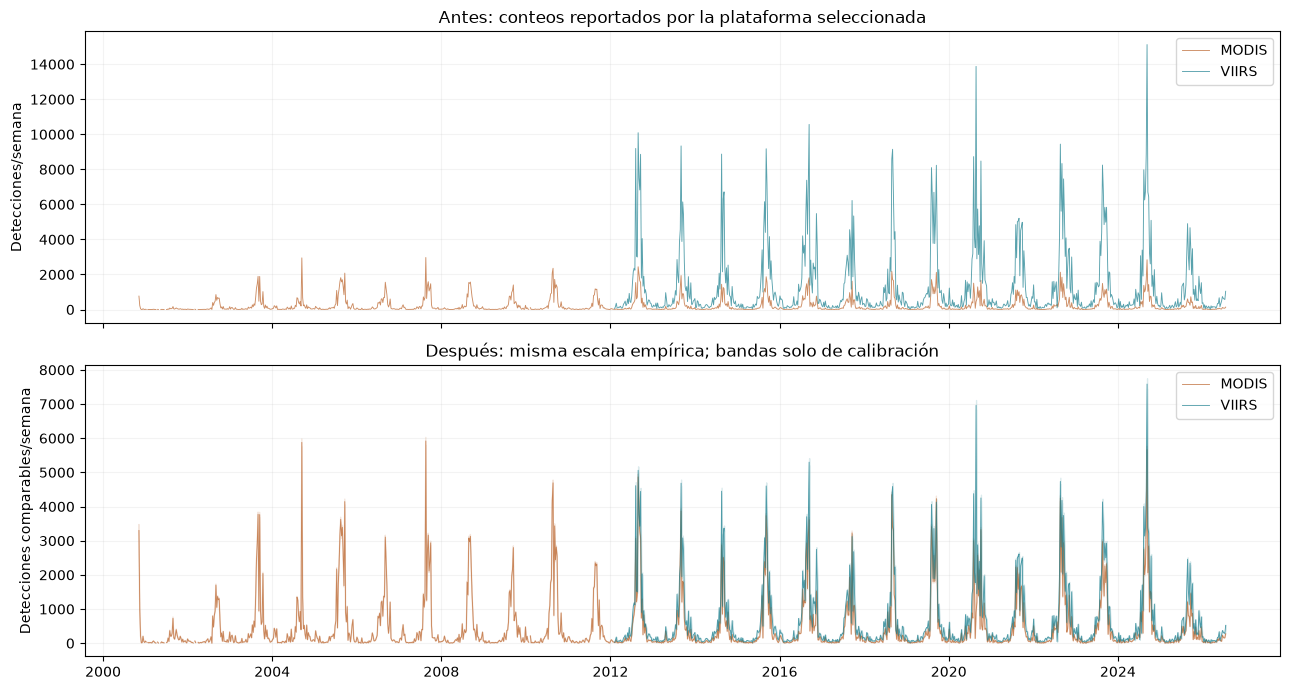

In [4]:
choice=pd.read_csv(P/'series/platform_selection.csv')
display(choice.groupby(['instrument','selected_platform'],dropna=False).size().rename('semanas').reset_index())
fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
for instrument,color in [('MODIS','#b85d22'),('VIIRS','#137b8b')]:
    d=national.loc[national.instrument.eq(instrument)].set_index('week_start_utc').sort_index()
    axes[0].plot(d.index,d.raw_count,color=color,alpha=.7,lw=.65,label=instrument)
    axes[1].plot(d.index,d.harmonized_count,color=color,alpha=.7,lw=.65,label=instrument)
    axes[1].fill_between(d.index,d.lower_bound,d.upper_bound,color=color,alpha=.15)
axes[0].set(title='Antes: conteos reportados por la plataforma seleccionada',ylabel='Detecciones/semana')
axes[1].set(title='Después: misma escala empírica; bandas solo de calibración',ylabel='Detecciones comparables/semana')
for ax in axes:ax.legend();ax.grid(alpha=.15)
fig.tight_layout();plt.show()

## 4. Validación temporal y espacial
La selección usa 2019–2021; el ajuste final de plataformas establecidas usa datos hasta 2021.
NOAA-21 entra mediante un puente de marzo–junio de 2023 que no cambia los factores anteriores.
Bloques de 200 km determinados antes del ajuste se reservan para prueba espacial.
El modelo global se conserva: las variantes estacionales/regionales mejoraban menos del 1 %
la log-verosimilitud condicional de validación.

Las métricas siguientes miden la asignación de una suma observada entre dos plataformas.
Son errores en pares con detección en ambas plataformas, NO errores contra incendios reales,
ni una validación de áreas sin observaciones. La prueba 2024–2025 se abrió después de congelar
la selección; el archivo JSON conserva el hash del modelo evaluado.

In [5]:
display(pd.read_csv(P/'model/inner_validation.csv').round(4))
outer=pd.read_csv(P/'model/outer_validation.csv')
final=pd.read_csv(P/'model/final_test_2024_2025.csv')
display(outer.round(4));display(final.round(4))
audit=json.loads((P/'model/final_evaluation.json').read_text())
assert hashlib.sha256((P/'model/model.json').read_bytes()).hexdigest()==audit['model_sha256_before_test']
assert not audit['model_changed_during_test']
print('Prueba final sin reajustar desde sus resultados: verificada.')

,candidate,pairs,conditional_nll,conditional_allocation_mae,conditional_allocation_rmse,mean_log_response_contrast
0,identity,60224,2.2315,1.8518,3.2092,0.0000
1,global,60224,1.4234,1.0363,1.5414,-0.4625
2,seasonal,60224,1.4228,1.0356,1.5411,-0.4615
3,regional_seasonal,60224,1.4226,1.0347,1.5395,-0.4638


,split,model,pairs,conditional_nll,conditional_allocation_mae,conditional_allocation_rmse,mean_log_response_contrast
0,temporal_validation,identity,63904,2.0449,1.6572,2.8138,0.0000
1,temporal_validation,selected,63904,1.4271,1.0299,1.5184,-0.4081
2,spatial_temporal_validation,identity,16113,2.4263,2.0425,3.8642,0.0000
3,spatial_temporal_validation,selected,16113,1.5059,1.1220,1.6702,-0.4603


,year,split,model,pairs,conditional_nll,conditional_allocation_mae,conditional_allocation_rmse,mean_log_response_contrast
0,2024,seen_space,identity,56313,2.2208,1.8327,3.8750,0.0000
1,2024,seen_space,selected,56313,1.4806,1.0987,1.7319,-0.3553
2,2024,heldout_space,identity,13206,2.7784,2.4538,6.2355,0.0000
3,2024,heldout_space,selected,13206,1.5892,1.2608,2.1758,-0.3902
4,2025,seen_space,identity,29704,1.6705,1.2530,1.9813,0.0000
5,2025,seen_space,selected,29704,1.3856,0.9710,1.4104,-0.2692
6,2025,heldout_space,identity,6108,1.7498,1.3279,2.2135,0.0000
7,2025,heldout_space,selected,6108,1.4146,0.9930,1.4411,-0.2647


Prueba final sin reajustar desde sus resultados: verificada.


## 5. Incertidumbre, artículo y lo que falta
Las bandas usan 100 réplicas bootstrap con pesos compartidos por bloques de 28 días. En el total
nacional se agrega cada réplica completa, conservando la correlación del factor entre celdas.
Son bandas de incertidumbre del factor de calibración bajo el modelo; no incluyen toda la
variabilidad de conteo, errores del supuesto Poisson, nubosidad o incendios omitidos.

Corrección v1.1: las fechas se normalizan explícitamente a nanosegundos antes de asignar
bloques. La revisión anterior usaba microsegundos como si fueran nanosegundos y producía
bandas degeneradas; esas bandas quedan retiradas. Se verificaron 237 bloques de entrenamiento,
cinco bloques del puente y 100 réplicas sin descartar ninguna. Los parámetros centrales
coinciden con la revisión anterior; no se volvió a seleccionar el modelo a partir del test.

Sofiev y Kouznetsov (2026) muestran que la observabilidad de FRP depende del área del píxel,
condiciones diurnas/nocturnas y fracción válida observada. Aquí se consideran esas limitaciones:
no trasladamos sus probabilidades globales a Perú ni usamos un operador FRP como corrección
de conteos. La corrección física requiere máscaras y geolocalización históricas todavía pendientes.
Artículo: https://gmd.copernicus.org/articles/19/10123/2026/
Límite oficial: https://geoservidorperu.minam.gob.pe/arcgis/rest/services/ServicioCFOI/MapServer/15

`frp_sum_mw` se conserva como diagnóstico, pero no es la variable armonizada en esta entrega.
Sumar FRP entre sobrevuelos no equivale a energía total emitida.

In [6]:
display(pd.Series({k:meta[k] for k in ['status','coverage_corrected','missing_policy','reference',
    'uncertainty_kind','complete_physical_harmonization']}))
draws=np.load(P/'model/bootstrap_parameters.npz')['theta']
assert np.ptp(draws,axis=0).min()>1e-4
display(pd.Series({'bloques entrenamiento':model['bootstrap_training_blocks'],
    'bloques puente':model['bootstrap_bridge_blocks'],'réplicas':len(draws)}))
assert not meta['complete_physical_harmonization']
print('API: GET /v1/empirical/series?start=2012-02-06&end=2026-07-27')
print('Añadir instrument=MODIS o VIIRS; añadir cell_id para una celda. end es exclusivo.')

status                                                                empirical_demo
coverage_corrected                                                             False
missing_policy                        unavailable; never a confirmed zero fire count
reference                          geometric-mean response of Aqua and Suomi-NPP ...
uncertainty_kind                   28-day block Bayesian-bootstrap calibration-fa...
complete_physical_harmonization                                                False
dtype: object

bloques entrenamiento    237
bloques puente             5
réplicas                 100
dtype: int64

API: GET /v1/empirical/series?start=2012-02-06&end=2026-07-27
Añadir instrument=MODIS o VIIRS; añadir cell_id para una celda. end es exclusivo.
